# 03 - Disengagement risk model
**Question:** using only days 1-76, can we predict which members will open the app **zero times** in days 77-90?

**Why split by time?** In real life you predict the future from the past. If we computed features using days 77-90 too, the model would 'cheat' (this is called *data leakage*).

In [1]:
import sys, json, warnings; sys.path.insert(0, ".."); warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from src.db import get_engine
from src.part2_pipeline import load_raw
from src.features import clean_metrics, compute_features
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.alpha": .25,
                     "figure.dpi": 110, "axes.titleweight": "bold", "axes.titlesize": 11})
BLUE, ORANGE, GREY = "#2f6db5", "#d9822b", "#8a8f98"
members, metrics, engagement = load_raw(get_engine())
truth = pd.read_csv("../data/synthetic_ground_truth.csv")
from src.part3_ml import *
get_ipython().run_line_magic('matplotlib', 'inline')
import matplotlib.pyplot as plt
mc, _ = clean_metrics(metrics)
X76, y = make_risk_dataset(members, mc, engagement)
X = X76[RISK_FEATURES]
print("members:", len(y), "| will disengage (label=1):", y.sum(), f"({y.mean():.1%})")

members: 500 | will disengage (label=1): 66 (13.2%)


## Baseline vs models
**Baseline rule:** 'no app opens in the last 7 days' -> predict disengaged.
**Models:** logistic regression and random forest.
**Evaluation:** 5-fold cross-validation - the members are split into 5 groups; each group is scored by a model trained on the other 4. With only ~66 positives, one single train/test split would be too noisy.

In [2]:
res = json.load(open("../outputs/risk_model_results.json"))
rows = [("Rule: no opens in last 7 days", res["baseline_rule_no_opens_last_7d"]["precision"], res["baseline_rule_no_opens_last_7d"]["recall"], res["baseline_rule_no_opens_last_7d"]["roc_auc"])]
for m in ["logistic_regression", "random_forest"]:
    rows.append((m + " @0.5", res[m]["at_threshold_0.5"]["precision"], res[m]["at_threshold_0.5"]["recall"], res[m]["roc_auc"]))
c = res["chosen_at_operating_threshold"]; rows.append((f"{res['chosen_model']} @ operating threshold {res['operating_threshold']}", c["precision"], c["recall"], res[res["chosen_model"]]["roc_auc"]))
display(pd.DataFrame(rows, columns=["approach","precision","recall","roc_auc"]))

,approach,precision,recall,roc_auc
0,Rule: no opens in last 7 days,0.711,0.818,0.884
1,logistic_regression @0.5,0.714,0.909,0.974
2,random_forest @0.5,0.852,0.788,0.979
3,random_forest @ operating threshold 0.489,0.855,0.803,0.979


### Reading the metrics
* **Precision** = of the members we flag, how many really disengage (low precision = many false alarms).
* **Recall** = of the members who really disengage, how many we caught (low recall = missed people).
* **ROC-AUC** = how well the score *ranks* at-risk members above safe ones, regardless of threshold (1.0 perfect, 0.5 coin flip).

**Which matters most for VI? Recall, held at an acceptable precision.** The cost of missing a member who is about to drift away (they lose a wellbeing benefit, the client loses value) is higher than the cost of one unnecessary friendly nudge. But we cannot flag everyone, because nudge fatigue makes people ignore VI. So we pick the threshold that keeps **recall >= 80%** and then look for the best precision. ROC-AUC is used to compare models; it is not the product metric.

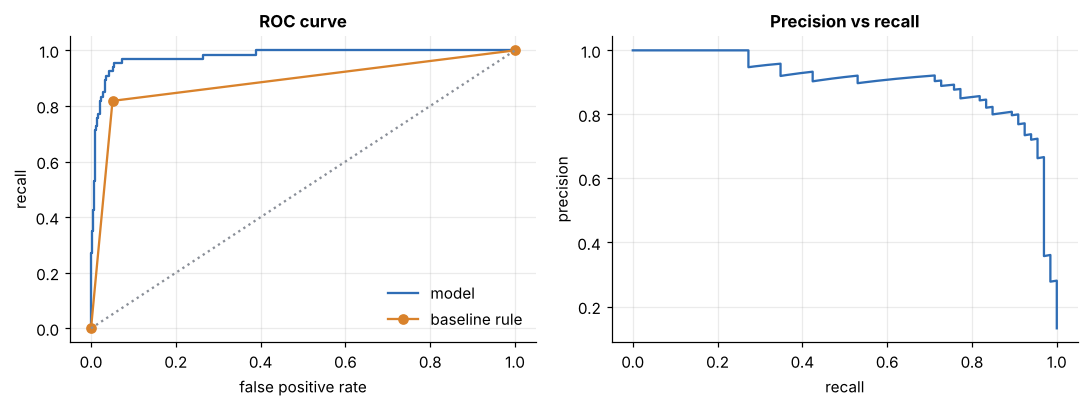

In [3]:
from sklearn.metrics import roc_curve, precision_recall_curve
oof = np.load("../outputs/risk_oof_proba.npy"); yy = np.load("../outputs/risk_labels.npy")
fpr, tpr, _ = roc_curve(yy, oof); p, r, _ = precision_recall_curve(yy, oof)
base = (X76["app_opens_7d"] == 0).astype(int).to_numpy()
fb, tb, _ = roc_curve(yy, base)
fig, ax = plt.subplots(1, 2, figsize=(10, 3.8))
ax[0].plot(fpr, tpr, color=BLUE, label="model"); ax[0].plot(fb, tb, color=ORANGE, marker="o", label="baseline rule"); ax[0].plot([0,1],[0,1], color=GREY, ls=":")
ax[0].set_title("ROC curve"); ax[0].set_xlabel("false positive rate"); ax[0].set_ylabel("recall"); ax[0].legend(frameon=False)
ax[1].plot(r, p, color=BLUE); ax[1].set_title("Precision vs recall"); ax[1].set_xlabel("recall"); ax[1].set_ylabel("precision"); plt.tight_layout()

## What drives risk?
Permutation importance: shuffle one feature and see how much the ROC-AUC drops - a big drop means the model relies on it.

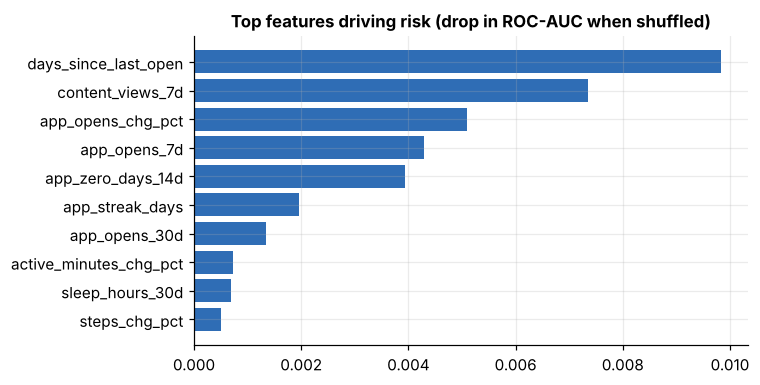

In [4]:
imp = pd.read_csv("../outputs/risk_feature_importance.csv", index_col=0)["auc_drop"].head(10)[::-1]
fig, ax = plt.subplots(figsize=(7, 3.6)); ax.barh(imp.index, imp.values, color=BLUE); ax.set_title("Top features driving risk (drop in ROC-AUC when shuffled)")
plt.tight_layout()

### Honest reading of the results
* The model beats the baseline mainly on **ranking** (higher ROC-AUC) and on precision at equal recall - the rule is a strong baseline because app-use drop-off is itself the signal.
* Top drivers are all **recent app behaviour** (days since last open, content views, change in opens). Wearable and mood features add little here **because the synthetic data was generated that way** - in real data we would expect more signal from them. We deliberately did **not** feed age, gender, company or job type to the model.
* The data is synthetic and the disengagement pattern is simple, so the high scores will not carry over to real members. The value of this notebook is the *method*: time-based split, baseline comparison, cross-validation, threshold chosen from a product goal.